## Model 2: DBQA results for Er$^{3+}$:LiYF$_4$

Loads the data of `Example_5_DBQA_Er_LiYF4_generate_data.ipynb` and analyses
1. convergence of the full DBQA on the two scales: free-ion manifolds and crystal-field levels,
2. the two-stage strategy restricted to the ground multiplet,
3. the cost of compiling this Hamiltonian, compared with Model 1 and with the XXZ chain of the Fig. 4 examples.

In [1]:
import os
import csv
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)

def plot_histories(histories, labels, key, ylabel, logy=True, filename=None):
    """Plot a recorded quantity over the DBQA iterations."""
    colors = plt.cm.inferno(np.linspace(0.1, 0.8, len(histories)))
    plt.figure(figsize=(5,5*6/8))
    for i, (h, l) in enumerate(zip(histories, labels)):
        plt.plot([r[key] for r in h], lw=2, color=colors[i], label=l, marker='.', ms=3)
    if logy:
        plt.yscale("log")
    plt.legend()
    plt.xlabel("Iterations")
    plt.ylabel(ylabel)
    plt.grid(True)
    if filename is not None:
        plt.savefig(f"pdfs_figures/{filename}.pdf", bbox_inches="tight")
    plt.show()

def iterations_to_reach(values, threshold):
    """First iteration after which `values` stay below `threshold` (None if never)."""
    values = np.asarray(values)
    above = np.nonzero(values > threshold)[0]
    if len(above) == 0:
        return 0
    return above[-1] + 1 if above[-1] + 1 < len(values) else None

[Qibo 0.2.14|INFO|2026-10-16 12:21:41]: Using numpy backend on /CPU:0


In [2]:
with open("simulation_results/Er_LiYF4_DBQA_L_9.pickle", "rb") as file:
    data = pickle.load(file)
energy_unit, energies, doublets, manifolds = data["energy_unit"], data["energies"], data["doublets"], data["manifolds"]
clusters = data["clusters"]
n_ground_clusters = sum(1 for g in clusters if g[0] < 16)  # clusters inside the ground multiplet
methods, NSTEPS = data["methods"], data["nsteps"]
n_levels = len(doublets) - 1  # without the padding
n_manifolds = len(manifolds) - 1
level_energies = energy_unit * (np.array([energies[g[0]] for g in doublets]) - energies[0])
print(f"{n_levels} physical levels in {n_manifolds} manifolds; {NSTEPS} iterations per method")

182 physical levels in 35 manifolds; 150 iterations per method


#### Two scales of convergence

For every iteration we summarise
- the **manifold infidelity**: $1-\min F$ over the projectors onto the physical manifolds (free-ion scale),
- the **ground-multiplet errors**: maximal energy error and $1-\min F$ of the 8 levels of $^4I_{15/2}$ (crystal-field scale),
- the maximal energy error over all physical levels.

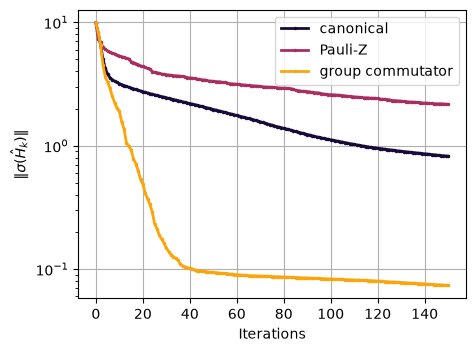

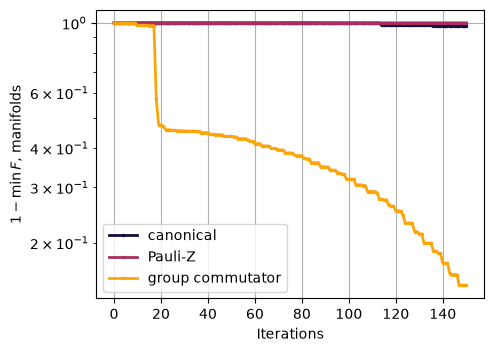

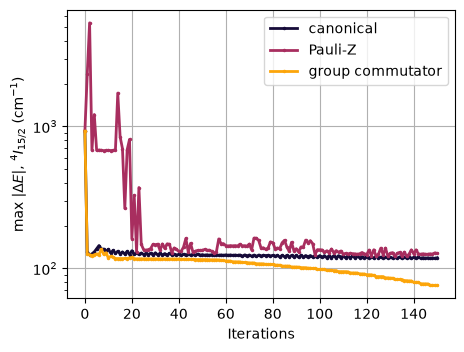

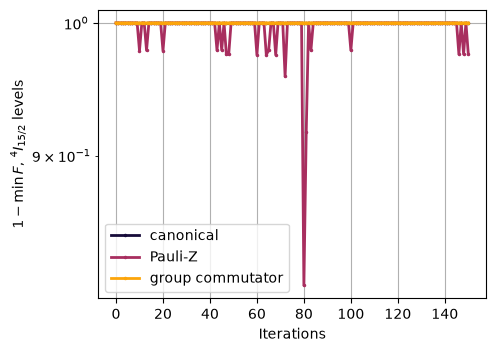

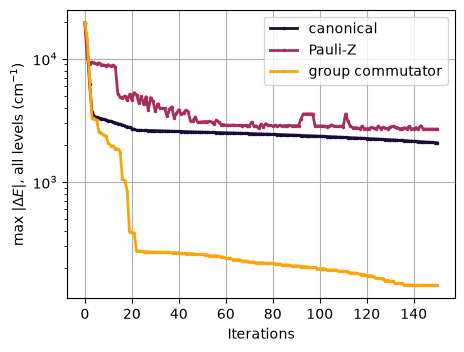

In [3]:
histories = []
for method in methods:
    history = []
    for r in data["stage1"][method]["history"]:
        history.append(dict(
            off_diagonal_norm=r["doublets"]["off_diagonal_norm"],
            manifold_infidelity=1 - np.min(r["manifolds"]["level_fidelity"][:n_manifolds]),
            ground_manifold_infidelity=1 - r["manifolds"]["level_fidelity"][0],
            ground_multiplet_energy_error=energy_unit * np.max(r["doublets"]["level_energy_error"][:8]),
            ground_multiplet_infidelity=1 - np.min(r["doublets"]["level_fidelity"][:8]),
            ground_multiplet_cluster_infidelity=1 - np.min(r["clusters"]["level_fidelity"][:n_ground_clusters]),
            all_levels_energy_error=energy_unit * np.max(r["doublets"]["level_energy_error"][:n_levels]),
        ))
    histories.append(history)

plot_histories(histories, methods, "off_diagonal_norm", r"$\| \sigma(\hat{H}_k) \|$", filename="Er_LiYF4_off_diagonal_norm")
plot_histories(histories, methods, "manifold_infidelity", r"$1-\min F$, manifolds", filename="Er_LiYF4_manifold_infidelity")
plot_histories(histories, methods, "ground_multiplet_energy_error", r"max $|\Delta E|$, $^4I_{15/2}$ (cm$^{-1}$)", filename="Er_LiYF4_ground_multiplet_energy_error")
plot_histories(histories, methods, "ground_multiplet_infidelity", r"$1-\min F$, $^4I_{15/2}$ levels", filename="Er_LiYF4_ground_multiplet_infidelity")
plot_histories(histories, methods, "all_levels_energy_error", r"max $|\Delta E|$, all levels (cm$^{-1}$)", filename="Er_LiYF4_all_levels_energy_error")

In [4]:
thresholds = [
    ("manifold_infidelity", 1e-2), ("manifold_infidelity", 1e-4),
    ("ground_manifold_infidelity", 1e-2), ("ground_manifold_infidelity", 1e-6),
    ("ground_multiplet_energy_error", 10.0), ("ground_multiplet_energy_error", 1.0),
    ("ground_multiplet_infidelity", 1e-2), ("ground_multiplet_cluster_infidelity", 1e-2),
    ("all_levels_energy_error", 100.0), ("all_levels_energy_error", 10.0),
]
print(f"{'quantity':32s} {'threshold':>9s} " + " ".join(f"{m:>17s}" for m in methods))
for key, threshold in thresholds:
    counts = [iterations_to_reach([r[key] for r in history], threshold) for history in histories]
    print(f"{key:32s} {threshold:9.0e} " + " ".join(f"{'> %d' % NSTEPS if c is None else c:>17}" for c in counts))

quantity                         threshold         canonical           Pauli-Z  group commutator
manifold_infidelity                  1e-02             > 150             > 150             > 150
manifold_infidelity                  1e-04             > 150             > 150             > 150
ground_manifold_infidelity           1e-02                 1                 5                 1
ground_manifold_infidelity           1e-06             > 150             > 150                26
ground_multiplet_energy_error        1e+01             > 150             > 150             > 150
ground_multiplet_energy_error        1e+00             > 150             > 150             > 150
ground_multiplet_infidelity          1e-02             > 150             > 150             > 150
ground_multiplet_cluster_infidelity     1e-02             > 150             > 150             > 150
all_levels_energy_error              1e+02             > 150             > 150             > 150
all_levels_energy_error    

In [5]:
fmt = {'float_kind': lambda x: f'{x:.1e}'}
print(f"After {NSTEPS} iterations:")
for method, history in zip(methods, histories):
    r = data["stage1"][method]["history"][-1]
    print(f"{method:17s} ||sigma|| {history[0]['off_diagonal_norm']:.2f} -> {history[-1]['off_diagonal_norm']:.2e}, "
          f"manifold 1-F (first 6) = {np.array2string(1 - r['manifolds']['level_fidelity'][:6], formatter=fmt)}")
    print(f"{'':17s} 4I15/2 |dE| (cm^-1) = {np.array2string(energy_unit * r['doublets']['level_energy_error'][:8], formatter=fmt)}")
    print(f"{'':17s} 4I15/2 1-F          = {np.array2string(1 - r['doublets']['level_fidelity'][:8], formatter=fmt)}")

After 150 iterations:
canonical         ||sigma|| 9.89 -> 8.22e-01, manifold 1-F (first 6) = [1.4e-05 3.2e-04 1.0e-03 2.0e-01 2.0e-01 6.4e-02]
                  4I15/2 |dE| (cm^-1) = [8.5e+01 1.0e+02 1.2e+02 8.4e+01 8.1e+01 8.1e+01 1.1e+02 1.1e+02]
                  4I15/2 1-F          = [1.0e+00 1.0e+00 1.0e+00 1.0e+00 9.2e-01 9.0e-01 1.0e+00 1.0e+00]
Pauli-Z           ||sigma|| 9.89 -> 2.16e+00, manifold 1-F (first 6) = [4.1e-04 1.4e-03 5.5e-02 2.9e-01 3.1e-01 3.7e-01]
                  4I15/2 |dE| (cm^-1) = [1.1e+02 1.3e+02 1.3e+02 1.1e+02 8.2e+01 8.2e+01 1.1e+02 1.1e+02]
                  4I15/2 1-F          = [9.8e-01 8.8e-01 6.8e-01 8.9e-01 9.2e-01 9.0e-01 6.5e-01 6.8e-01]
group commutator  ||sigma|| 9.89 -> 7.38e-02, manifold 1-F (first 6) = [3.1e-10 6.0e-11 6.9e-07 4.4e-11 6.0e-09 5.7e-07]
                  4I15/2 |dE| (cm^-1) = [5.5e+01 6.7e+01 7.6e+01 6.4e+01 6.6e+01 6.5e+01 6.2e+01 6.9e+01]
                  4I15/2 1-F          = [9.4e-01 7.3e-01 9.5e-01 7.7e-01 9.1e-01 8.8e

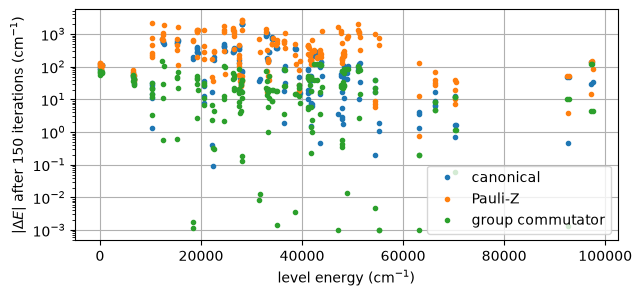

In [6]:
# energy error per level after the last iteration, against the level energy
plt.figure(figsize=(7, 3))
for method in methods:
    r = data["stage1"][method]["history"][-1]["doublets"]
    plt.semilogy(level_energies[:n_levels], energy_unit * r["level_energy_error"][:n_levels] + 1e-3, ".", label=method)
plt.xlabel(r"level energy (cm$^{-1}$)"); plt.ylabel(r"$|\Delta E|$ after %d iterations (cm$^{-1}$)" % NSTEPS)
plt.legend(); plt.grid(True)
plt.savefig("pdfs_figures/Er_LiYF4_final_level_errors.pdf", bbox_inches="tight")
plt.show()

#### Stage 2: DBQA inside the ground multiplet

Stage 2 starts from every stage-1 run at the first iteration at which the ground manifold is isolated to $1-F<10^{-3}$ and to $1-F<10^{-6}$, and runs the Model 1 strategies on the 4-qubit block. The restriction error (block eigenvalues against the exact ground-multiplet levels) is the price of switching early; the error against the exact levels is at most the stage-2 error plus the restriction error.

In [7]:
block_thresholds = [("energy", 1.0), ("energy", 0.1), ("infidelity", 1e-2)]
fmt = {'float_kind': lambda x: f'{x:.1e}'}
print(f"{'stage 1':17s} {'switch':>9s} {'k':>4s} {'restriction':>11s}   {'stage 2':17s} {'its to <1':>9s} {'<0.1 cm^-1':>10s} {'1-F<1e-2':>8s} {'final max|dE|':>13s} {'vs exact <=':>11s}")
for (method, threshold), s2 in data["stage2"].items():
    if s2 is None:
        print(f"{method:17s} {threshold:9.0e}    -  not isolated within {NSTEPS} iterations")
        continue
    for block_method, run in s2["runs"].items():
        series = {
            "energy": [data["block_unit"] * np.max(r["doublets"]["level_energy_error"]) for r in run["history"]],
            "infidelity": [1 - np.min(r["doublets"]["level_fidelity"]) for r in run["history"]],
        }
        counts = [iterations_to_reach(series[q], t) for q, t in block_thresholds]
        counts = [f"> {len(run['history']) - 1}" if c is None else str(c) for c in counts]
        final = series["energy"][-1]
        print(f"{method:17s} {threshold:9.0e} {s2['k_switch']:4d} {s2['leakage_error']:9.1e} cm^-1   {block_method:17s} "
              f"{counts[0]:>9s} {counts[1]:>10s} {counts[2]:>8s} {final:10.1e} cm^-1 {final + s2['leakage_error']:8.1e} cm^-1")

stage 1              switch    k restriction   stage 2           its to <1 <0.1 cm^-1 1-F<1e-2 final max|dE| vs exact <=
canonical             1e-03    1   1.2e+01 cm^-1   canonical                74      > 100    > 100    1.7e-01 cm^-1  1.3e+01 cm^-1
canonical             1e-03    1   1.2e+01 cm^-1   Pauli-Z                  11         31       67    2.4e-03 cm^-1  1.2e+01 cm^-1
canonical             1e-03    1   1.2e+01 cm^-1   group commutator         27      > 100    > 100    1.3e-01 cm^-1  1.3e+01 cm^-1
canonical             1e-06    -  not isolated within 150 iterations
Pauli-Z               1e-03   24   4.6e+01 cm^-1   canonical                98      > 100    > 100    9.1e-01 cm^-1  4.7e+01 cm^-1
Pauli-Z               1e-03   24   4.6e+01 cm^-1   Pauli-Z                  12         52       63    6.5e-03 cm^-1  4.6e+01 cm^-1
Pauli-Z               1e-03   24   4.6e+01 cm^-1   group commutator         31      > 100    > 100    3.8e-01 cm^-1  4.6e+01 cm^-1
Pauli-Z               1e

canonical         dE per state (cm^-1) = [3.9e-01 3.9e-01 1.9e-01 1.9e-01 -3.9e-01 -3.9e-01 -1.9e-01 -1.9e-01
 1.1e-01 1.1e-01 -1.1e-01 -1.1e-01 2.6e-05 2.6e-05 -4.7e-04 -4.7e-04]
Pauli-Z           dE per state (cm^-1) = [2.9e-03 2.9e-03 1.0e-07 1.0e-07 -2.9e-03 -2.9e-03 -1.0e-07 -1.0e-07
 7.3e-08 7.3e-08 -7.4e-08 -7.4e-08 8.6e-07 8.6e-07 -3.8e-06 -3.8e-06]
group commutator  dE per state (cm^-1) = [3.1e-01 3.1e-01 5.2e-09 5.2e-09 -3.1e-01 -3.1e-01 7.5e-07 7.5e-07 6.5e-07
 6.5e-07 -1.4e-06 -1.4e-06 4.1e-06 4.1e-06 -2.1e-05 -2.1e-05]


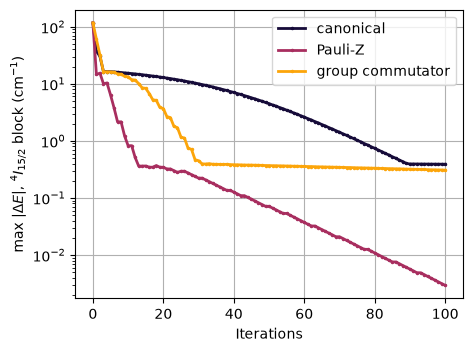

In [8]:
# residual errors per state after stage 2 (group-commutator stage 1, 1-F < 1e-6): equal and opposite pairs
s2 = data["stage2"][("group commutator", 1e-6)]
for block_method, run in s2["runs"].items():
    print(f"{block_method:17s} dE per state (cm^-1) = {np.array2string(data['block_unit'] * run['history'][-1]['doublets']['energy_error'], formatter=fmt)}")
block_histories = [[dict(e=data["block_unit"] * np.max(r["doublets"]["level_energy_error"])) for r in run["history"]] for run in s2["runs"].values()]
plot_histories(block_histories, list(s2["runs"]), "e", r"max $|\Delta E|$, $^4I_{15/2}$ block (cm$^{-1}$)", filename="Er_LiYF4_stage2_energy_error")

#### Compilation cost

The Pauli decomposition of the embedded Hamiltonian determines the cost of a Trotterized evolution oracle with the CNOT-ladder compilation of `add_pauli_rotation`. We compare with Model 1 (Ce:YAG, 4 qubits) and with the XXZ chain of the Fig. 4 examples, whose second-order step on $L$ qubits uses 3 CNOTs per bond.

In [9]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
h, _ = crystal_field_hamiltonian([getattr(f11cf, name) for name in coeff], coeff, energy_unit=energy_unit)
decomposition = pauli_decomposition(h.backend.to_numpy(h.matrix))
weights = np.bincount([pauli_weight(s) for s in decomposition], minlength=h.nqubits + 1)
print(f"Er:LiYF4: {len(decomposition)} Pauli strings out of {4**h.nqubits}; by weight 0..9: {weights}")
print(f"CNOTs per Trotter step: first order {trotter_cnot_count(decomposition, 1)}, second order {trotter_cnot_count(decomposition, 2)}")

f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
coeff_ce = dict(CE_YAG_HU2011["fitted"], EAVG=0.0)
h_ce, _ = crystal_field_hamiltonian([f1cf.EAVG] + [getattr(f1cf, name) for name in CE_YAG_TENSORS], coeff_ce)
decomposition_ce = pauli_decomposition(h_ce.backend.to_numpy(h_ce.matrix))
print(f"Ce:YAG:   {len(decomposition_ce)} Pauli strings; CNOTs per first-order step {trotter_cnot_count(decomposition_ce, 1)}")

import sys
sys.path.append(os.path.abspath("../../src"))
from db_doi.utils_XXZ_compilation import XXZ_compilation_line
for L in [4, 9]:
    xxz = XXZ_compilation_line(L)
    print(f"XXZ L={L}: {len(xxz.terms)} Pauli terms; CNOTs per second-order step {sum(1 for g in xxz.circuit(0.1).queue if len(g.qubits) == 2)}")

Er:LiYF4: 93184 Pauli strings out of 262144; by weight 0..9: [    1    17   156   926  3794 10804 21204 27530 21309  7443]
CNOTs per Trotter step: first order 1073026, second order 2146036


Ce:YAG:   71 Pauli strings; CNOTs per first-order step 272
XXZ L=4: 9 Pauli terms; CNOTs per second-order step 12
XXZ L=9: 24 Pauli terms; CNOTs per second-order step 36


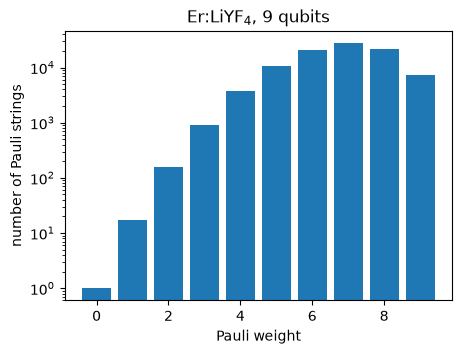

In [10]:
plt.figure(figsize=(5, 3.5))
plt.bar(range(h.nqubits + 1), weights)
plt.yscale("log"); plt.xlabel("Pauli weight"); plt.ylabel("number of Pauli strings")
plt.title("Er:LiYF$_4$, 9 qubits")
plt.savefig("pdfs_figures/Er_LiYF4_pauli_weights.pdf", bbox_inches="tight")
plt.show()

In [11]:
with open("simulation_results/Er_LiYF4_compilation_L_9.pickle", "wb") as file:
    pickle.dump(dict(n_pauli=len(decomposition), weights=weights,
                     cnot_first_order=trotter_cnot_count(decomposition, 1), cnot_second_order=trotter_cnot_count(decomposition, 2),
                     n_pauli_ce_yag=len(decomposition_ce), cnot_first_order_ce_yag=trotter_cnot_count(decomposition_ce, 1)), file)